# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

**The data itself doesn’t say. There is no campaign ID or year column, so you can’t count campaigns from the file. The campaign column is something different: it counts how many times a given client was contacted during that client’s campaign.

The authors’ paper states that the dataset collected is related to 17 campaigns that occurred between May 2008 and November 2010, corresponding to a total of 79354 contacts. A second paper by the same authors repeats this, saying the data collected included 17 campaigns executed between May 2008 and November 2010.**

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from sklearn.pipeline import make_pipeline
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             average_precision_score, precision_recall_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
import time
import warnings



In [2]:
df = pd.read_csv('data/bank-additional/bank-additional-full.csv', sep = ';')


In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



**Analysis**

**Analysis of the features:**
The raw file has no null values (0 NaN across all 41,188 rows). Missing information is hidden in two other ways, described below. The dataset has 20 input features and one target (y).

**Missing values and type issues:**

“unknown” is the real missing value in six columns: default (8,597), education (1,731), housing (990), loan (990), job (330) and marital (80). The column types are correct, but these values should be treated as missing or as their own category.

pdays = 999 is a placeholder, not a real number. It appears in 39,673 rows (96%) and means “never contacted before”. Left as a number it would badly distort any model, so it should be missing or encoded with a flag.

Column names contain dots (emp.var.rate), which are best replaced with underscores.

There are around 12 duplicate records.

**default: only 3 “yes” values and 21% unknown, so it carries almost no signal.**

**The target column name:**

The target column name y tells the reader nothing, and subscribed says what the column holds: whether the client subscribed to the term deposit or not. Better option is to rename the column y to subscribed.

In [4]:
# Names of columns that contain "unknown"
cols_with_unknown = df.columns[(df == 'unknown').any()]
print(list(cols_with_unknown))
# Count of unknowns per column
counts_unk = (df == 'unknown').sum()
print(counts_unk[counts_unk > 0])

n_pdays_999 = (df['pdays'] == 999).sum()
print(n_pdays_999)
#number of default = yes rows
default_yes = (df['default'] == 'yes').sum()
print(default_yes)
default_no = (df['default'] == 'no').sum()
print(default_no)



['job', 'marital', 'education', 'default', 'housing', 'loan']
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64
39673
3
32588


**Duplicate Rows**

In [5]:
# Count duplicate rows
print(df.duplicated().sum())          # 12

# Show the duplicates (the second and later copies)
df[df.duplicated()]

# Show every copy, including the first occurrence, so you can compare them
df[df.duplicated(keep=False)].sort_values(list(df.columns))

12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


In [6]:
#remove duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)              # (41176, 21)
print(df.duplicated().sum()) # 0

(41176, 21)
0


**Clean the features and Data**

In [7]:

# replace pdays value 999 with NaN
print((df['pdays'] == 999).sum())
df['pdays'] = df['pdays'].replace(999, np.nan)
print(df['pdays'].isna().sum())

#Replace column names contain dots, with underscores.
df.columns = df.columns.str.replace('.', '_', regex=False)
print(df.columns.tolist())

#Replace target column name y with sunscribed
df = df.rename(columns={'y': 'subscribed'})

print(df.columns.tolist())
print(df['subscribed'].value_counts())



39661
39661
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y']
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'subscribed']
subscribed
no     36537
yes     4639
Name: count, dtype: int64


**Data Visualization**

A scatter plot is not great for the target, because subscribed is only 0 or 1. But plotted for a numeric features age and campaign.

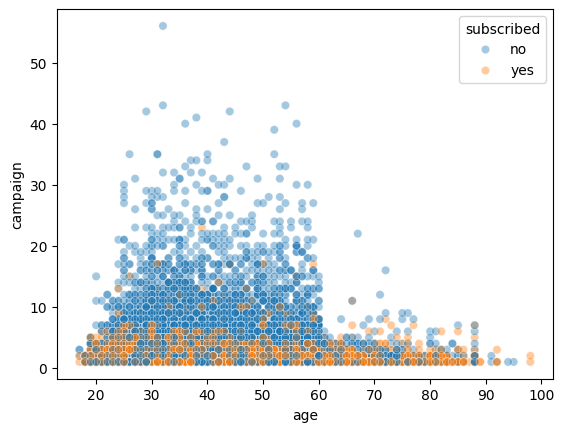

In [8]:
sns.scatterplot(data=df, x='age', y='campaign', hue='subscribed', alpha=0.4)
plt.savefig("images/data_analysis_scatter1.png")
plt.show()

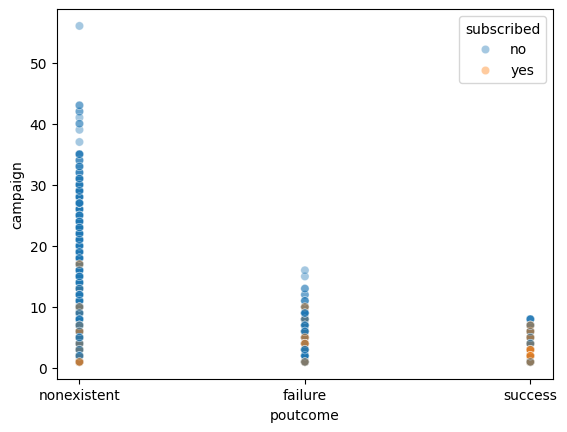

In [9]:
sns.scatterplot(data=df, x='poutcome', y='campaign', hue='subscribed', alpha=0.4)
plt.savefig("images/data_analysis_scatter2.png")
plt.show()

**Bar charts of the yes rate by category:**

The mean of a 0/1 column is the share of “yes”, so groupby().mean() gives the subscription rate for each category.

The red dashed line is the overall rate of about 11%, so you can see which categories sit above or below it.

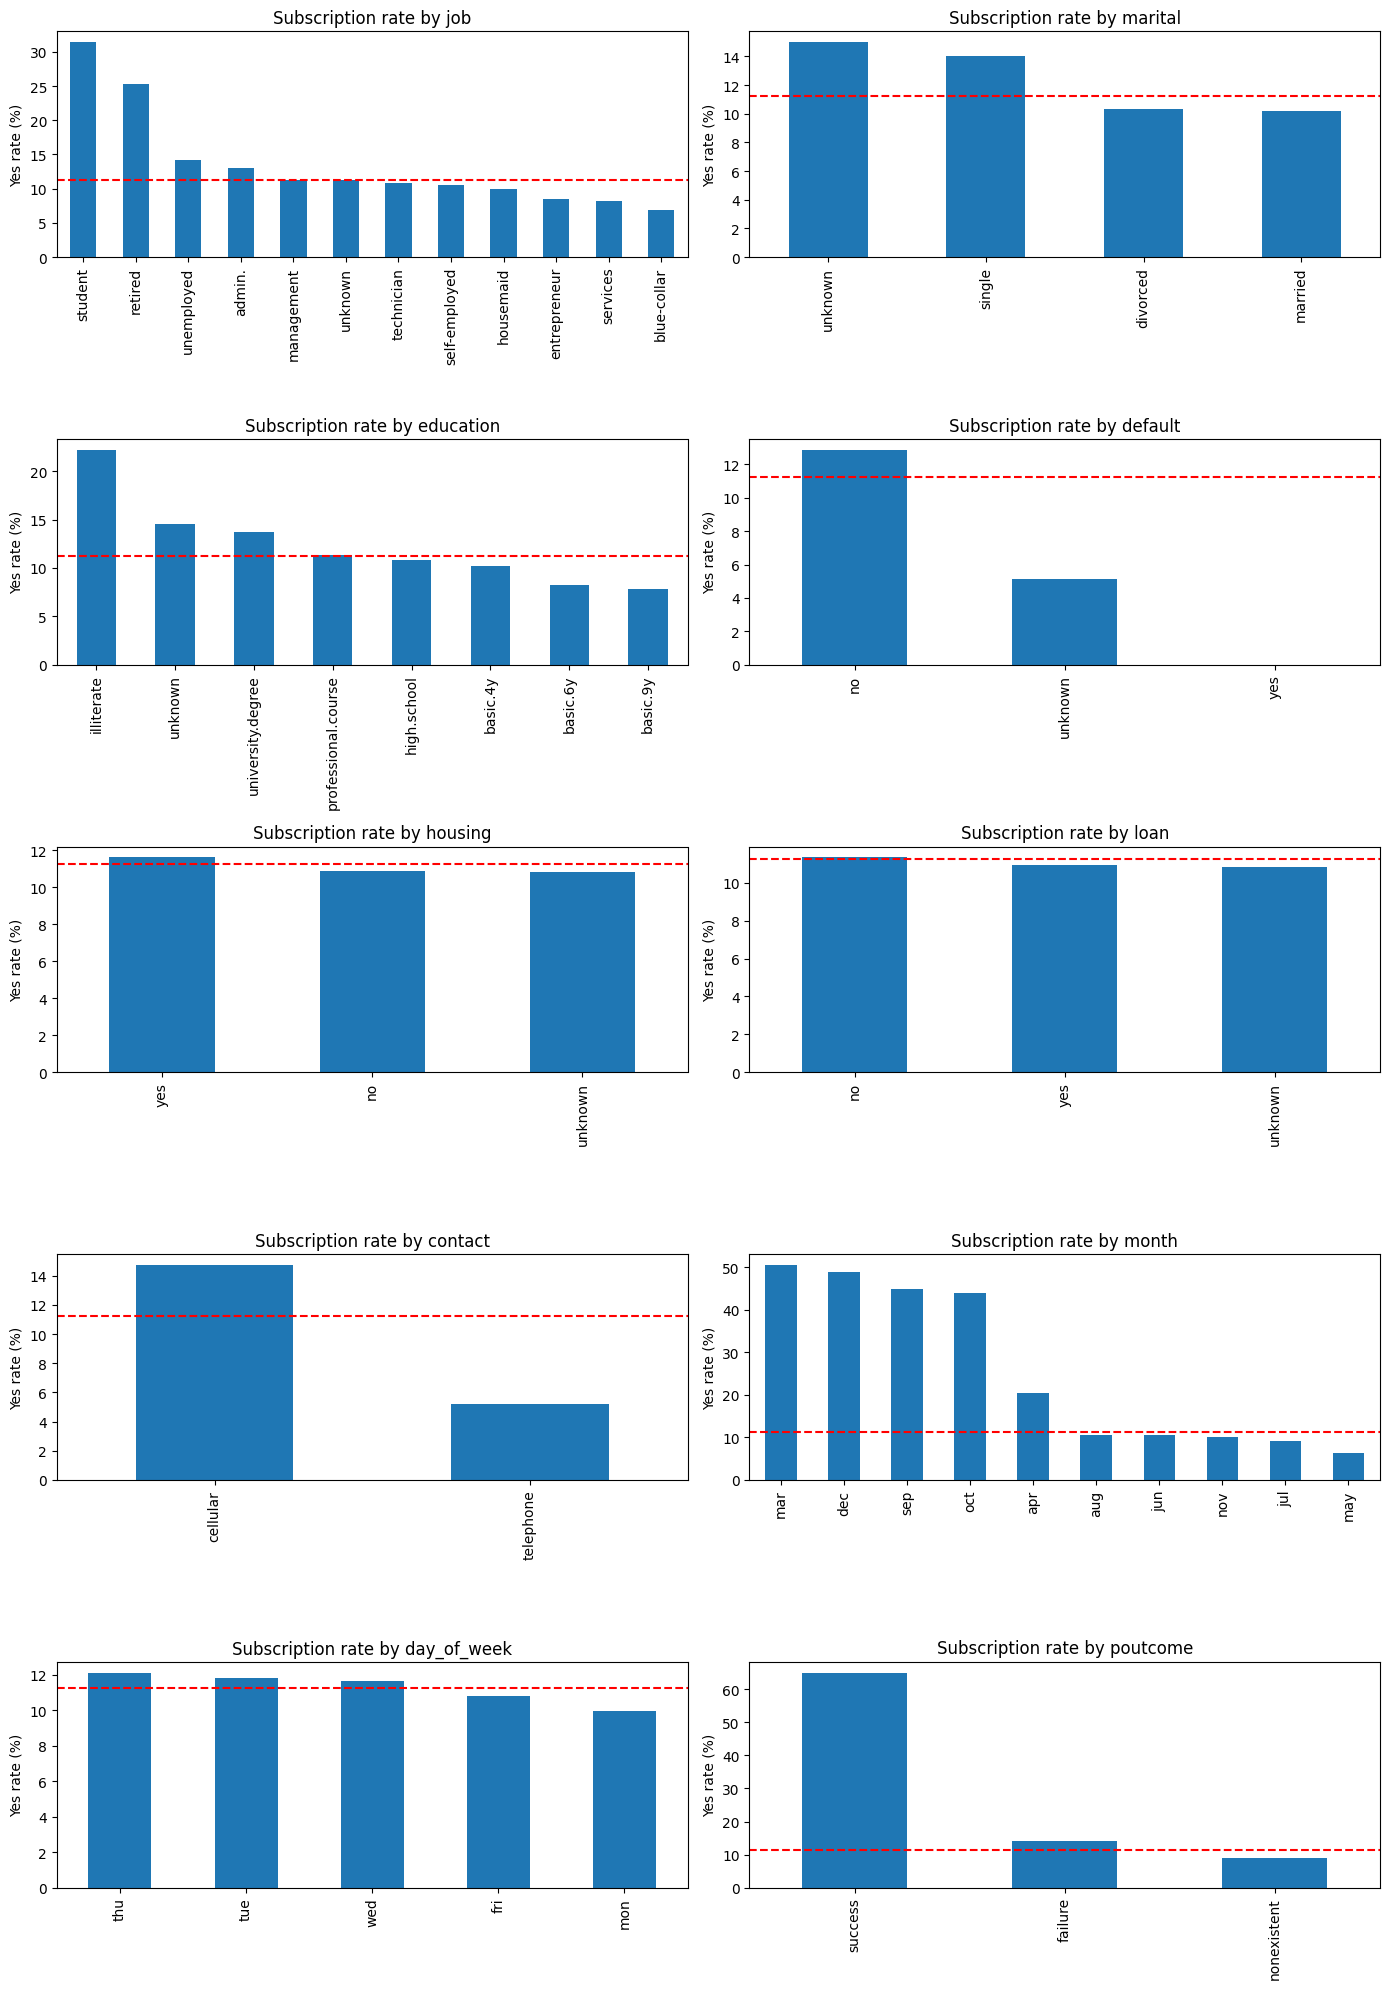

In [10]:
#Bar charts of the yes rate by category
df['subscribed'] = df['subscribed'].map({'no': 0, 'yes': 1})
X = df.drop('subscribed', axis=1)

categorical_columns = X.select_dtypes(include=['object']).columns.tolist()

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
overall = df['subscribed'].mean()

for ax, col in zip(axes.ravel(), categorical_columns):
    rate = df.groupby(col)['subscribed'].mean().sort_values(ascending=False) * 100
    rate.plot(kind='bar', ax=ax)
    ax.axhline(overall * 100, color='red', linestyle='--', label='overall')
    ax.set_title(f'Subscription rate by {col}')
    ax.set_ylabel('Yes rate (%)')
    ax.set_xlabel('')

plt.tight_layout()
plt.savefig("images/data_analysis_barplot.png")
plt.show()

**Box plots of numeric columns by outcome:**

/tmp/ipykernel_116203/3735204448.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['no', 'yes'])
/tmp/ipykernel_116203/3735204448.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['no', 'yes'])
/tmp/ipykernel_116203/3735204448.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['no', 'yes'])
/tmp/ipykernel_116203/3735204448.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['no', 'yes'])
/tmp/ipykernel_116203/3735204448.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(

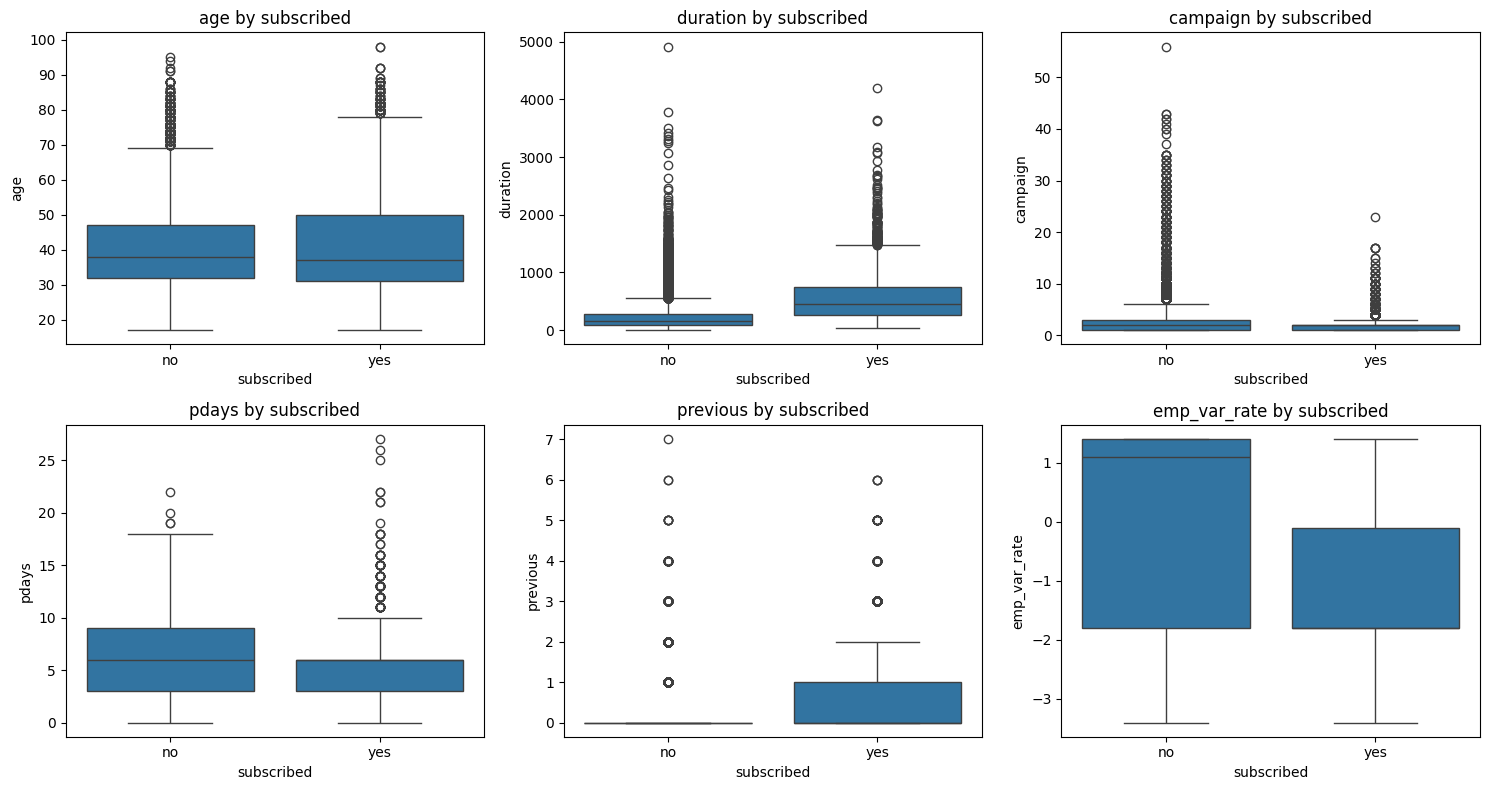

In [11]:

numerical_columns = X.select_dtypes(include=['float64', 'int64']).columns.tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), numerical_columns):
    sns.boxplot(data=df, x='subscribed', y=col, ax=ax)
    ax.set_title(f'{col} by subscribed')
    ax.set_xticklabels(['no', 'yes'])

plt.tight_layout()
plt.savefig("images/data_analysis_boxPlot.png")
plt.show()

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

**Business objective:** The bank runs telephone marketing campaigns to sell long-term term deposits, and each call costs time and money. The goal is to build a classification model that predicts whether a client contacted by the bank’s telemarketing campaign will sign up for the term deposit (success) or not sign up (failure). The target is the binary column subscribed (yes/no). The model would help the bank focus its calls on clients most likely to subscribe, improving the campaign’s success rate and lowering its cost per sale.

**subscribed (formerly y) is the target.** It records whether the client signed up for the term deposit in the current contact: yes means success, no means failure.

**poutcome is a feature, not the target.** It records the outcome of the previous campaign (success, failure or nonexistent).

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  object 
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  object 
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           1515 non-null   float64
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  object 
 15  emp_var_rate    41176 non-null  float64
 16  cons_price_idx  41176 non-null  float64
 17  cons_conf_idx   41176 non-null 

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

**Use Case 1:** Use only the bank-information columns (first 7): age, job, marital, education, default, housing, loan.
Encode the target and prepare the features (one-hot for categories, scaling for age).

In [13]:

# 1. Select features and target
X = df.iloc[:, :7].copy()
y = df["subscribed"]
print(X.dtypes)
print(y.value_counts())


# 2. Define column groups
num_cols = ["age"]
cat_cols = ["job", "marital", "education", "default", "housing", "loan"]

# 3. Build the preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),                          # age -> mean 0, std 1
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),    # categories -> 0/1 columns
])



age           int64
job          object
marital      object
education    object
default      object
housing      object
loan         object
dtype: object
subscribed
0    36537
1     4639
Name: count, dtype: int64


**Preview the encoded result**

In [14]:
X_encoded = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()
X_preview = pd.DataFrame(X_encoded.toarray() if hasattr(X_encoded, "toarray") else X_encoded,
                         columns=feature_names)
print("Raw shape:", X.shape, "-> Encoded shape:", X_preview.shape)
X_preview.head()

Raw shape: (41176, 7) -> Encoded shape: (41176, 34)


,num__age,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid,cat__job_management,cat__job_retired,cat__job_self-employed,cat__job_services,cat__job_student,...,cat__education_unknown,cat__default_no,cat__default_unknown,cat__default_yes,cat__housing_no,cat__housing_unknown,cat__housing_yes,cat__loan_no,cat__loan_unknown,cat__loan_yes
0,1.533143,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,1.629107,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-0.290177,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
3,-0.002284,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,1.533143,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

Split the prepared data into training and test sets. We stratify on `y` so both sets keep the same share of "yes".

In [15]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,       # 30% held out for testing
    random_state=42,     # reproducible split
    stratify=y,          # keep the ~11% "yes" rate in both sets
)


print(X_train.shape, X_test.shape)
print(y_train.mean().round(4), y_test.mean().round(4))   # both about 0.1127


(28823, 7) (12353, 7)
0.1127 0.1127


In [16]:
print("Train:", X_train.shape, "| Test:", X_test.shape)
summary = pd.DataFrame({
    "Rows": [len(y), len(y_train), len(y_test)],
    "Yes count": [y.sum(), y_train.sum(), y_test.sum()],
    "Yes rate": [y.mean(), y_train.mean(), y_test.mean()],
}, index=["Full data", "Train", "Test"]).round(4)
summary

Train: (28823, 7) | Test: (12353, 7)


,Rows,Yes count,Yes rate
Full data,41176,4639,0.1127
Train,28823,3247,0.1127
Test,12353,1392,0.1127


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

**The baseline is the performance of a "model" that ignores the features and always predicts the majority class ("no").
Any real classifier has to beat it.**

In [17]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

print("Majority class:", "no" if baseline.classes_[0] == 0 else "yes")
print("Train accuracy:", round(baseline.score(X_train, y_train), 4))
print("Test accuracy :", round(accuracy_score(y_test, pred), 4))
print("Precision     :", precision_score(y_test, pred, zero_division=0))
print("Recall        :", recall_score(y_test, pred))
print("F1            :", f1_score(y_test, pred))
print("ROC AUC       :", roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]))



Majority class: no
Train accuracy: 0.8873
Test accuracy : 0.8873
Precision     : 0.0
Recall        : 0.0
F1            : 0.0
ROC AUC       : 0.5


**Baseline to beat: about 88.7% accuracy.** It is the share of "no" customers, so it equals `1 - yes_rate(0.1127)`.
It scores 0 on precision, recall and F1 for "yes" and 0.5 ROC AUC (no skill), because it never predicts "yes".

A real model needs test accuracy above 0.8873 to be better than doing nothing. That’s a hard bar here, since the model has to improve on an 89% score.





### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

Logistic regression on the 7 bank-information features, using the preprocessing from Problem 5
inside a `Pipeline`

In [18]:

logreg = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

logreg.fit(X_train, y_train)

train_pred = logreg.predict(X_train)
test_pred  = logreg.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, train_pred))
print('Test accuracy :', accuracy_score(y_test, test_pred))
print(classification_report(y_test, test_pred, zero_division=0))

print("Fitted. Number of encoded features:", logreg[-1].coef_.shape[1])
print("Share of test customers predicted 'yes':", logreg.predict(X_test).mean())




Train accuracy: 0.8873469104534573
Test accuracy : 0.88731482231037
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     10961
           1       0.00      0.00      0.00      1392

    accuracy                           0.89     12353
   macro avg       0.44      0.50      0.47     12353
weighted avg       0.79      0.89      0.83     12353

Fitted. Number of encoded features: 34
Share of test customers predicted 'yes': 0.0


### Problem 9: Score the Model

What is the accuracy of your model?

In [19]:

print("Logistic regression  train:", round(logreg.score(X_train, y_train), 4), "| test:", round(logreg.score(X_test, y_test), 4))
print("Baseline (always no) train:", round(baseline.score(X_train, y_train), 4), "| test:", round(baseline.score(X_test, y_test), 4))


proba = logreg.predict_proba(X_test)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_test, proba), 3), "(0.5 = no skill)")
print("PR AUC :", round(average_precision_score(y_test, proba), 3), f"(no skill = {y_test.mean():.3f})")

def report(pred, label):
    return {"Model": label,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred, zero_division=0)}

rows = [report(logreg.predict(X_test), "Logistic regression (threshold 0.5)"),
        report((proba >= 0.15).astype(int), "Logistic regression (threshold 0.15)"),
        report(baseline.predict(X_test), "Baseline (always no)")]
results = pd.DataFrame(rows).round(3)
print(results)




Logistic regression  train: 0.8873 | test: 0.8873
Baseline (always no) train: 0.8873 | test: 0.8873
ROC AUC: 0.65 (0.5 = no skill)
PR AUC : 0.206 (no skill = 0.113)
                                  Model  Accuracy  Precision  Recall     F1
0   Logistic regression (threshold 0.5)     0.887      0.000    0.00  0.000
1  Logistic regression (threshold 0.15)     0.796      0.209    0.29  0.243
2                  Baseline (always no)     0.887      0.000    0.00  0.000


## Confusion matrix for the model (rows = actual, columns = predicted)

            pred no  pred yes
actual no     10961         0
actual yes     1392         0


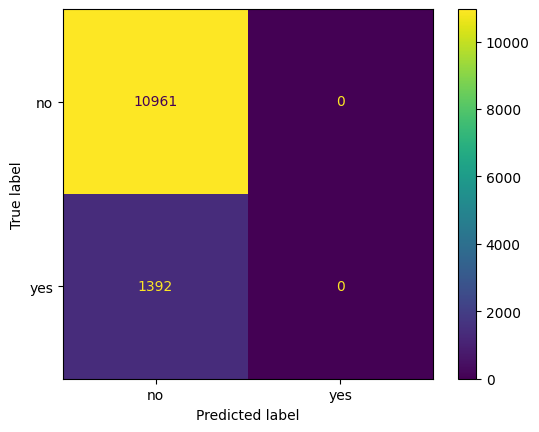

In [20]:
results = pd.DataFrame(confusion_matrix(y_test, logreg.predict(X_test)),
             index=["actual no", "actual yes"], columns=["pred no", "pred yes"])

print(results)
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test,
                                      display_labels=['no', 'yes'])
plt.savefig("images/confusion_matrix.png")
plt.show()


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

|Model|Train Time \(s\)|Train Accuracy|Test Accuracy|
|---|---|---|---|
|Decision Tree|0\.795|0\.9189|0\.8630|
|KNN|0\.057|0\.8904|0\.8779|
|Logistic Regression|0\.112|0\.8873|0\.8873|
|SVM|61\.748|0\.8882|0\.8873|



In [21]:

models = {
    'Baseline (always no)': DummyClassifier(strategy="most_frequent"),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(random_state=42),
}

results = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])

    start = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - start

    results.append({
        'Model': name,
        'Train Time (s)': round(fit_time, 3),
        'Train Accuracy': round(pipe.score(X_train, y_train), 4),
        'Test Accuracy': round(pipe.score(X_test, y_test), 4),
    })

results_df = pd.DataFrame(results).set_index('Model')
results_df

,Train Time (s),Train Accuracy,Test Accuracy
Model,,,
Baseline (always no),0.078,0.8873,0.8873
Logistic Regression,0.117,0.8873,0.8873
KNN,0.054,0.8904,0.8779
Decision Tree,0.774,0.9189,0.8630
SVM,66.127,0.8882,0.8873


**What the table shows:**

**No model beats the baseline.** Logistic regression and the SVM tie it at 0.8873 because they predict “no” for everyone. KNN and the decision tree score lower on the test set.

**The decision tree overfits the most.** Its training accuracy is the highest (0.9189) but its test accuracy is the lowest (0.863). A default tree has no depth limit, so it memorizes the training data.

**KNN overfits a little.** Training accuracy is 0.8904 versus 0.8779 on the test set.

**Training time:** The SVM takes about 61.748 seconds, versus under a second for the others.

**What to say in the answer.** With only the 7 bank-information features, none of the default models improves on predicting “no” every time, so accuracy shows no benefit from modelling. The simplest model (logistic regression) is as good as any and the fastest. Since accuracy hides how well each model finds subscribers, a stronger comparison would add recall, precision, F1 and ROC AUC for the “yes” class.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric



## Improved grid search
Changes from the original cell:
- **`class_weight`** added for logistic regression and the tree (data is only ~11% "yes").
- **KNN grid** extended to 101 neighbors (the best value, 51, was at the edge of the old grid).
- **Stratified, shuffled folds** so each fold keeps the same share of "yes".
- Prints the full results table (parameters were being truncated).

---SVM at 0.5640 is barely better than guessing (0.5), and it took 146 seconds. With these features it is not worth its cost.

---Decision tree (0.6478), logistic regression (0.6477) and KNN (0.6407) are close, and the differences are small enough to be noise. I’d report them as roughly equal.

---Decision tree is the fastest and best, so it is a sensible pick for this feature set.

In [22]:
cv = StratifiedKFold(3, shuffle=True, random_state=42)
param_grids = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=42),
                            {'model__C': [0.01, 0.1, 1, 10],
                             'model__class_weight': [None, 'balanced']}),
    'KNN': (KNeighborsClassifier(),
            {'model__n_neighbors': [11, 21, 51, 101],
             'model__weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
                      {'model__max_depth': [3, 5, 8, 12],
                       'model__min_samples_split': [2, 20, 100],
                       'model__class_weight': [None, 'balanced']}),
    'SVM': (SVC(random_state=42),
            {'model__C': [0.1, 1], 'model__kernel': ['rbf']}),
}

best_models, rows = {}, []
for name, (model, grid) in param_grids.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    start = time.time()
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    rows.append({'Model': name,
                 'Best Params': {k.replace('model__', ''): v for k, v in gs.best_params_.items()},
                 'Best CV AUC': round(gs.best_score_, 4),
                 'Time (s)': round(time.time() - start, 1)})

cv_results = pd.DataFrame(rows).set_index('Model')
pd.set_option("display.max_colwidth", None)
cv_results



,Best Params,Best CV AUC,Time (s)
Model,,,
Logistic Regression,"{'C': 0.01, 'class_weight': 'balanced'}",0.6477,6.0
KNN,"{'n_neighbors': 101, 'weights': 'uniform'}",0.6407,147.0
Decision Tree,"{'class_weight': None, 'max_depth': 8, 'min_samples_split': 100}",0.6478,7.6
SVM,"{'C': 1, 'kernel': 'rbf'}",0.5640,152.9


Yes, KNN is slow here, and that is expected. KNN’s fit is nearly instant, because it only stores the data. The cost is in scoring, where every validation row is compared with every training row.  That adds up to 158 seconds, and the decision tree and logistic regression do none of this work.

## Evaluate the tuned models on the test set
Cross-validation AUC only tells you how the model ranks customers. This cell adds the metrics that matter for an
imbalanced target. The decision threshold is picked on out-of-fold **training** predictions (best F1), then applied
once to the test set, so the test numbers stay honest.

In [23]:
def get_score(model, X):
    return model.decision_function(X) if hasattr(model[-1], "decision_function") else model.predict_proba(X)[:, 1]

eval_rows = []
for name, est in best_models.items():
    method = "decision_function" if hasattr(est[-1], "decision_function") else "predict_proba"
    oof = cross_val_predict(est, X_train, y_train, cv=cv, method=method)
    oof = oof if oof.ndim == 1 else oof[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    thr = t[np.argmax((2 * p * r / (p + r + 1e-9))[:-1])]

    s = get_score(est, X_test)
    pred = (s >= thr).astype(int)
    eval_rows.append({'Model': name,
                      'Accuracy': accuracy_score(y_test, pred),
                      'ROC AUC': roc_auc_score(y_test, s),
                      'PR AUC': average_precision_score(y_test, s),
                      'Precision': precision_score(y_test, pred, zero_division=0),
                      'Recall': recall_score(y_test, pred),
                      'F1': f1_score(y_test, pred)})

test_results = pd.DataFrame(eval_rows).set_index('Model').round(3)
print("Baseline accuracy (always 'no'):", round(1 - y_test.mean(), 3), "| PR AUC no-skill:", round(y_test.mean(), 3))
test_results

Baseline accuracy (always 'no'): 0.887 | PR AUC no-skill: 0.113


,Accuracy,ROC AUC,PR AUC,Precision,Recall,F1
Model,,,,,,
Logistic Regression,0.627,0.653,0.207,0.167,0.579,0.259
KNN,0.715,0.651,0.225,0.183,0.440,0.258
Decision Tree,0.682,0.661,0.211,0.178,0.504,0.263
SVM,0.435,0.591,0.178,0.131,0.716,0.222


## Use Case  2: Include all features:
** Feature engineering **
- Drop `duration` (only known after the call -> leaks the target).
- `pdays == 999` means "never contacted": drop pdays
- Collapse the sparse `default` column (only 3 people say "yes").
- There is no gender column in this dataset; the closest sensitive features are `age` and `marital`.
- Keep "unknown" as its own category rather than imputing (missingness can be informative).

In [24]:

X = df.drop(columns=["subscribed", "duration", "pdays"]).copy()
X["contacted_before"] = (X["previous"] > 0).astype(int)
X = X.drop(columns=["default"])

cat = X.select_dtypes(exclude="number").columns.tolist()
num = X.select_dtypes(include="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)


def make_pipe(clf):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("pre", pre), ("clf", clf)])

## Hyper parameter tuning using all columns
Tuned on **ROC AUC** (not accuracy, which a "always say no" model already scores ~0.89 on).
SVM is tuned on a 8,000-row subsample for speed, then refit on the full training set.

In [25]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=3000),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(),
        {"clf__n_neighbors": [15, 31, 51, 101], "clf__weights": ["uniform", "distance"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
        {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [1, 20, 50, 100]}),
    "SVM": (SVC(),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01]}),
}

best = {}
for name, (clf, grid) in grids.items():
    t0 = time.time()
    if name == "SVM":
        idx = X_train.sample(8000, random_state=0).index
        gs = GridSearchCV(make_pipe(clf), grid, scoring="roc_auc", cv=3, n_jobs=-1)
        gs.fit(X_train.loc[idx], y_train.loc[idx])
    else:
        gs = GridSearchCV(make_pipe(clf), grid, scoring="roc_auc", cv=cv, n_jobs=-1)
        gs.fit(X_train, y_train)
    best[name] = gs
    print(f"{name:20s} best CV AUC {gs.best_score_:.3f}  {gs.best_params_}  ({time.time()-t0:.0f}s)")

Logistic Regression  best CV AUC 0.788  {'clf__C': 0.1, 'clf__class_weight': 'balanced'}  (13s)
KNN                  best CV AUC 0.778  {'clf__n_neighbors': 101, 'clf__weights': 'uniform'}  (57s)
Decision Tree        best CV AUC 0.789  {'clf__max_depth': 7, 'clf__min_samples_leaf': 20}  (16s)
SVM                  best CV AUC 0.696  {'clf__C': 1, 'clf__gamma': 'scale'}  (28s)


**Bottom line:** logistic regression and the decision tree are your top candidates. Logistic regression gives you interpretable coefficients and smooth scores. The tree gives you explainable rules. Pick based on which you need to explain, since their accuracy is equivalent.
KNN is a fair third choice, and the SVM isn’t worth the extra time here.

## Evaluate with better metrics
Decision threshold is chosen on out-of-fold *training* predictions (maximizing F1), then applied
once to the test set, so the test numbers stay honest.

In [26]:
def score(model, X):
    return model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]

rows = []
for name, gs in best.items():
    print(gs.best_params_.items())
    params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    print(params)
    final = make_pipe(grids[name][0].set_params(**params))
    t0 = time.time(); final.fit(X_train, y_train); ft = time.time() - t0
    method = "decision_function" if name in ("Logistic Regression", "SVM") else "predict_proba"
    oof = cross_val_predict(make_pipe(grids[name][0].set_params(**params)), X_train, y_train,
                            cv=3, method=method, n_jobs=-1)
    oof = oof if oof.ndim == 1 else oof[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    thr = t[np.argmax((2 * p * r / (p + r + 1e-9))[:-1])]
    s = score(final, X_test)
    pred = (s >= thr).astype(int)
    rows.append([name, round(ft, 1), accuracy_score(y_test, pred), roc_auc_score(y_test, s),
                 average_precision_score(y_test, s), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred)])

results = pd.DataFrame(rows, columns=["Model", "Fit Time (s)", "Accuracy", "ROC AUC",
                                      "PR AUC", "Precision", "Recall", "F1"]).round(3)
results

dict_items([('clf__C', 0.1), ('clf__class_weight', 'balanced')])
{'C': 0.1, 'class_weight': 'balanced'}
dict_items([('clf__n_neighbors', 101), ('clf__weights', 'uniform')])
{'n_neighbors': 101, 'weights': 'uniform'}
dict_items([('clf__max_depth', 7), ('clf__min_samples_leaf', 20)])
{'max_depth': 7, 'min_samples_leaf': 20}
dict_items([('clf__C', 1), ('clf__gamma', 'scale')])
{'C': 1, 'gamma': 'scale'}


,Model,Fit Time (s),Accuracy,ROC AUC,PR AUC,Precision,Recall,F1
0,Logistic Regression,1.6,0.875,0.803,0.450,0.454,0.528,0.488
1,KNN,0.2,0.869,0.794,0.435,0.439,0.579,0.499
2,Decision Tree,0.2,0.877,0.806,0.452,0.465,0.583,0.517
3,SVM,120.1,0.886,0.696,0.402,0.494,0.444,0.467


##Ranking quality (ROC AUC and PR AUC)

**The decision tree and logistic regression** are essentially tied (AUC 0.806 vs 0.803, PR AUC 0.452 vs 0.450). That’s about an 80% chance that a real subscriber is scored above a non-subscriber.

KNN is slightly lower (0.794), and the SVM is clearly the weakest (0.696).
PR AUC is about 0.45 for the top models, roughly four times the no-skill level of 0.113 (the base rate). That’s the more telling number for imbalanced data.

##Yes/no predictions (precision, recall, F1)

**Precision about 0.45:** Of every 100 customers a model flags, about 45 subscribe, compared with 11 if you called at random.
**Recall 0.53–0.58:** The tree, KNN and logistic regression find about 53–58% of real subscribers. The SVM finds only 44%.

The decision tree has the best F1 (0.517) and the highest recall (0.583), with good precision. KNN trades precision for recall (lowest precision, 0.439).

## Chart based on the metrics
The chart compares the four tuned models on ROC AUC, precision, recall and F1 from your test-set table.

**Decision tree:** It has the tallest or near-tallest bars on ROC AUC (0.806), recall (0.583) and F1 (0.517).

**Logistic regression:** It is close behind, and its ROC AUC of 0.803 is effectively tied with the tree.

**KNN:** It has high recall (0.579) but the lowest precision (0.439).

**SVM:** Its ROC AUC bar (0.696) and recall bar (0.444) are visibly the shortest. Its precision (0.494) is the highest, but only because it makes fewer “yes” predictions.

I left accuracy off the chart on purpose. All four models sit around 0.87–0.89, so those bars would look nearly identical and hide the real differences.

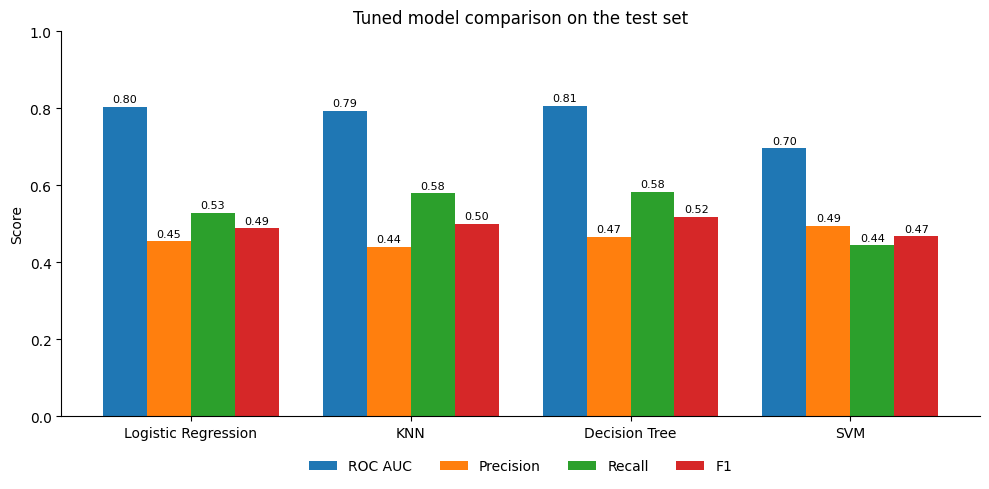

In [27]:

# Test-set results (paste your own `results` dataframe here instead if you have it)
results = pd.DataFrame({
    "Model":     ["Logistic Regression", "KNN", "Decision Tree", "SVM"],
    "ROC AUC":   [0.803, 0.794, 0.806, 0.696],
    "Precision": [0.454, 0.439, 0.465, 0.494],
    "Recall":    [0.528, 0.579, 0.583, 0.444],
    "F1":        [0.488, 0.499, 0.517, 0.467],
})

metrics = ["ROC AUC", "Precision", "Recall", "F1"]
x = np.arange(len(results))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
for i, m in enumerate(metrics):
    bars = ax.bar(x + (i - 1.5) * width, results[m], width, label=m)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(results["Model"])
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Tuned model comparison on the test set")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Metrics that depend on a threshold:**(DT)

These describe the model’s yes/no predictions at one cutoff.

**Accuracy (0.877):** The share of all predictions that are correct. With 88.7% of customers saying “no”, a model that always predicts “no” scores 0.887, so accuracy has to beat that baseline to mean anything. Here it doesn’t, so it says almost nothing about these models.

**Precision (0.465):** Of the customers the model flags as “yes”, the share who really subscribe. In practice, of every 100 people you call, about 46 subscribe. A random call would reach about 11, so that’s roughly 4 times better targeting. Precision is the metric to watch when each contact costs money.

**Recall (0.583):** Of all customers who would subscribe, the share the model finds. The tree finds about 58 of every 100 real subscribers and misses 42. Recall is the metric to watch when a missed customer is expensive.

**F1 (0.517):** The harmonic mean of precision and recall. It’s a single balanced score, but it assumes missing a subscriber and wasting a call are equally bad, which is rarely true in practice. It also ignores true negatives entirely.

**Metrics that don’t depend on a threshold**

These describe how well the model ranks customers.

**ROC AUC (0.806):** The probability that a randomly chosen subscriber gets a higher score than a randomly chosen non-subscriber. 0.5 is a coin flip and 1.0 is perfect. So 0.806 means the model ranks correctly about 81% of the time.

**PR AUC (0.452):** The area under the precision-recall curve. Its baseline is the base rate (0.113), not 0.5, so 0.452 is about 4 times the no-skill level. For imbalanced data like this, PR AUC is usually more informative than ROC AUC, because ROC AUC can look good even when precision is poor.

**Visualization - Decision Tree**

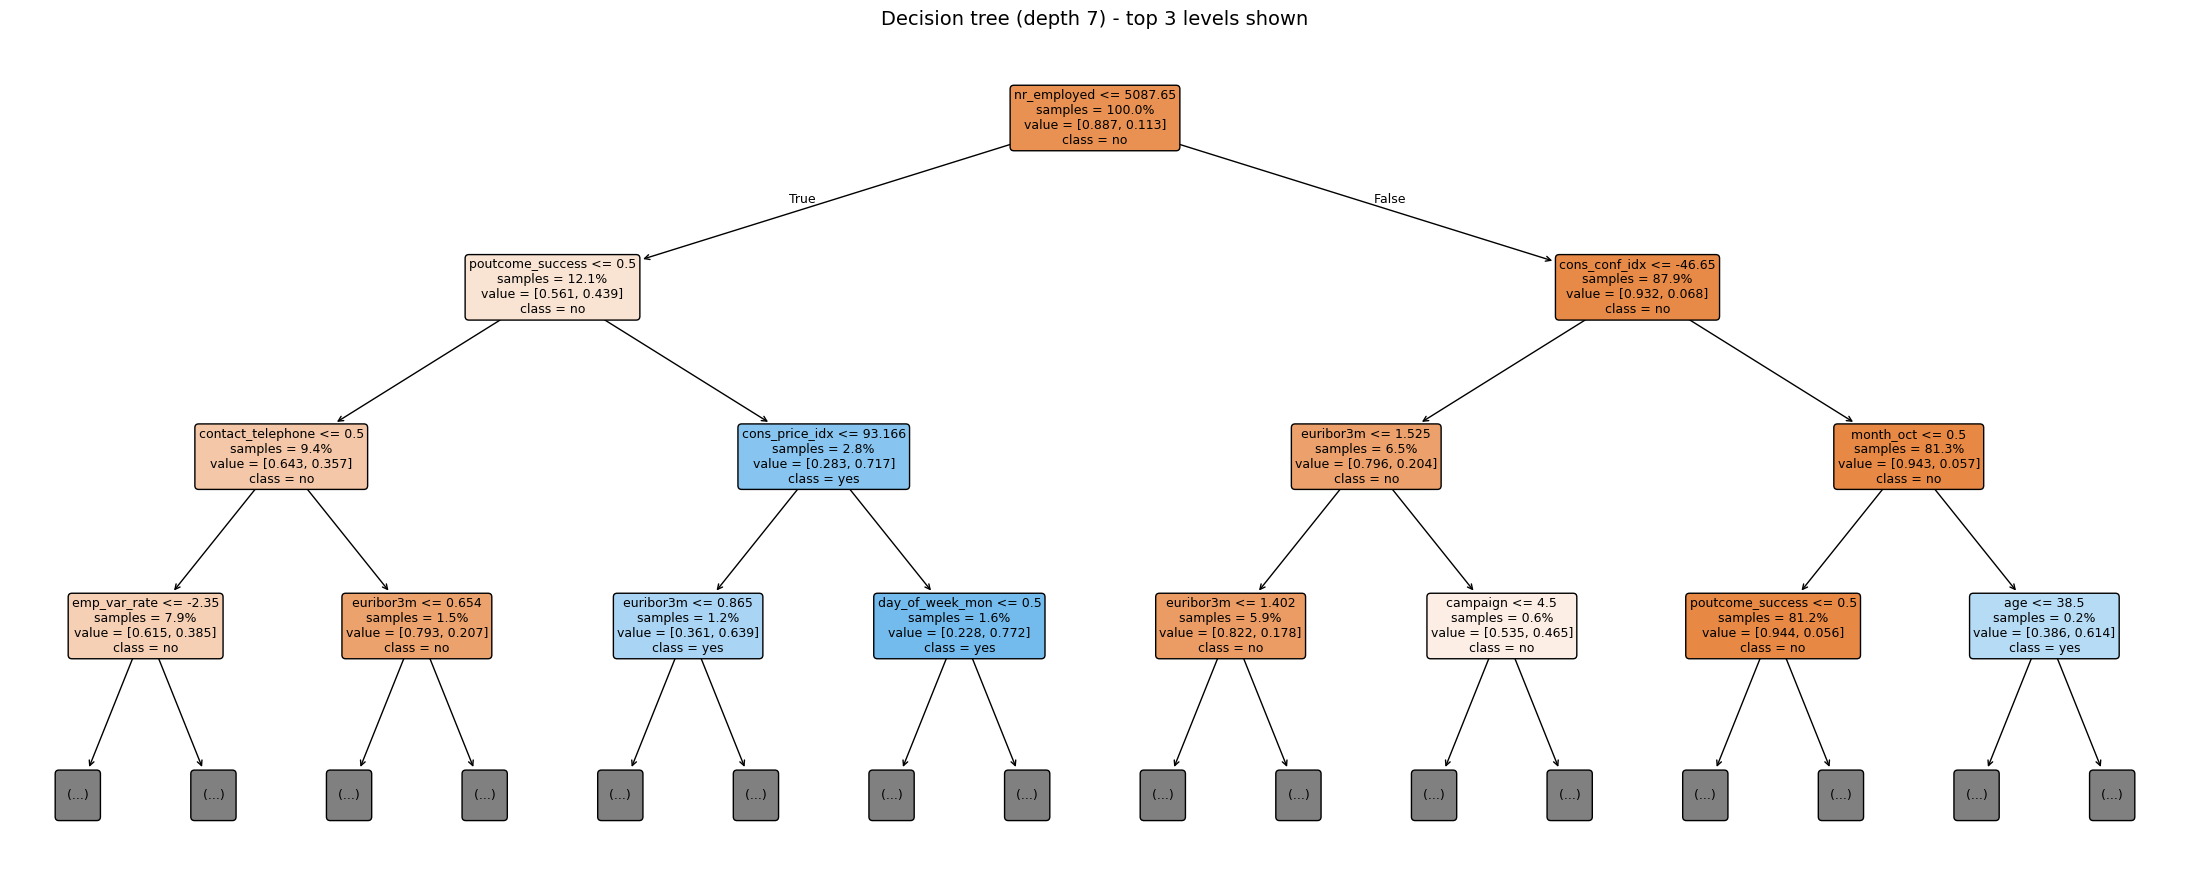

|--- nr_employed <= 5087.65
|   |--- poutcome_success <= 0.50
|   |   |--- contact_telephone <= 0.50
|   |   |   |--- emp_var_rate <= -2.35
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- emp_var_rate >  -2.35
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- contact_telephone >  0.50
|   |   |   |--- euribor3m <= 0.65
|   |   |   |   |--- class: 1
|   |   |   |--- euribor3m >  0.65
|   |   |   |   |--- truncated branch of depth 4
|   |--- poutcome_success >  0.50
|   |   |--- cons_price_idx <= 93.17
|   |   |   |--- euribor3m <= 0.87
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- euribor3m >  0.87
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- cons_price_idx >  93.17
|   |   |   |--- day_of_week_mon <= 0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- day_of_week_mon >  0.50
|   |   |   |   |--- truncated branch of depth 3
|--- nr_employed >  5087.65
|   |--- cons_conf_idx <= -46.65
|   |   |--- eurib

In [28]:

warnings.filterwarnings("ignore")

# Trees don't need scaling, so numeric columns pass through unchanged.
pre = ColumnTransformer([("num", "passthrough", num),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
pipe = Pipeline([("pre", pre),
                 ("clf", DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, random_state=42))])
pipe.fit(X_train, y_train)

tree = pipe[-1]
feature_names = [n.split("__", 1)[1] for n in pipe[:-1].get_feature_names_out()]

# --- plot the top 3 levels (the full depth-7 tree is too large to read) ---
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, feature_names=feature_names, class_names=["no", "yes"],
          max_depth=3, filled=True, rounded=True, proportion=True,
          impurity=False, fontsize=9, ax=ax)
ax.set_title("Decision tree (depth 7) - top 3 levels shown", fontsize=14)
plt.tight_layout()
plt.savefig("images/decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

# --- the same top levels as text rules ---
print(export_text(tree, feature_names=feature_names, max_depth=3))

##Plot Decision boundaries:
Made a 2×2 plot of the decision boundaries for all four models.

 **What the plot shows:**
• We can only draw a boundary in two dimensions, so each model here is retrained on just two features, euribor3m and cons_conf_idx. These are not the full models from the earlier tables.

•	I picked that pair because it kept most of the signal: a tree on those two alone reached about 0.80 AUC, close to the full model.

•	The blue region is where the model predicts "yes", and the orange region is where it predicts "no". The threshold is each model's best-F1 cutoff on the training data. Without it, the unweighted models would predict "no" everywhere and the plot would be one flat color.

**How each model draws the line:**

**•	Logistic regression:** A single straight line, since it can only separate the data linearly. That is why its AUC on these two features (0.745) is the lowest. A curved relationship is out of its reach.

**•	KNN:** A smooth but irregular boundary that follows where the data actually clusters. With k=101, it avoids tiny islands but still bends to the data (AUC 0.797).

**•	Decision tree:** Boundaries made only of vertical and horizontal edges, because each split uses one feature at a time. The thin slivers show overfitting to small clusters (AUC 0.795).

**•	SVM (RBF):** Smooth curved shapes, and the most rounded of the four (AUC 0.784). Fit it on a 10,000-row sample because it's slow.



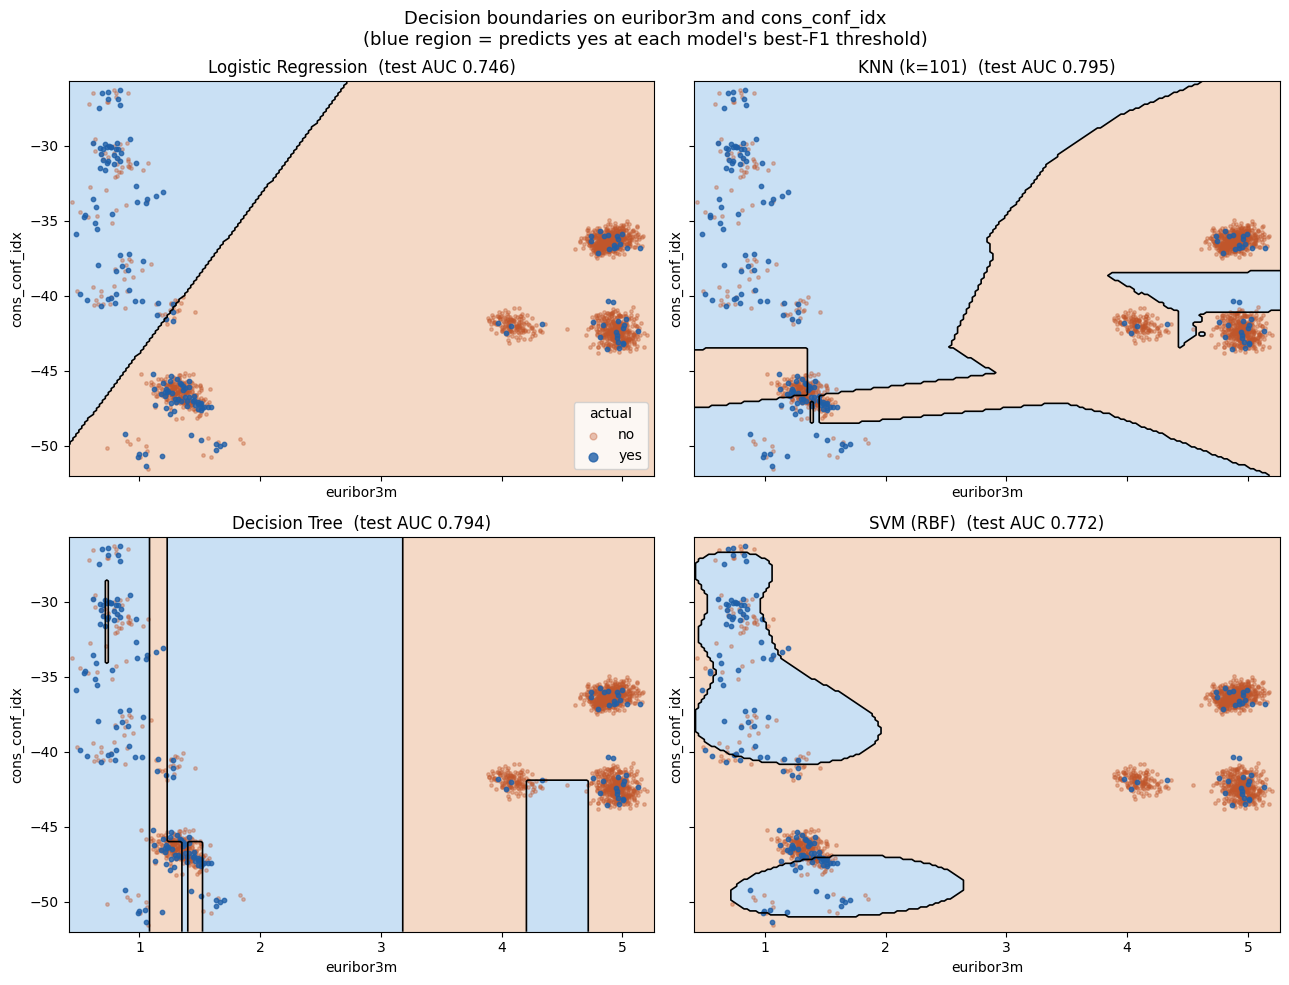

In [29]:


# Decision boundaries need 2 features. Change these to any two numeric columns.
F1, F2 = "euribor3m", "cons_conf_idx"
#F1, F2 = "age", "cons_price_idx"

X = df[[F1, F2]]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced")),
    "KNN (k=101)":         make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=101)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, random_state=42),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(C=1, class_weight="balanced")),
}

def score(model, A):
    return model.decision_function(A) if hasattr(model, "decision_function") else model.predict_proba(A)[:, 1]

# grid covering the data range
pad = lambda s: (s.min() - 0.05 * np.ptp(s), s.max() + 0.05 * np.ptp(s))
(x0, x1), (y0, y1) = pad(X[F1]), pad(X[F2])
xx, yy = np.meshgrid(np.linspace(x0, x1, 200), np.linspace(y0, y1, 200))
grid = pd.DataFrame({F1: xx.ravel(), F2: yy.ravel()})

rng = np.random.RandomState(0)
show = X_test.sample(1500, random_state=0)          # points to draw
show_y = y_test.loc[show.index]
# These features take few distinct values, so points overlap heavily; jitter them for display only
jx = show[F1] + rng.normal(0, 0.02 * np.ptp(X[F1]), len(show))
jy = show[F2] + rng.normal(0, 0.02 * np.ptp(X[F2]), len(show))

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
bg = ListedColormap(["#F4D9C6", "#C9E0F4"])          # orange = predict no, blue = predict yes
for ax, (name, model) in zip(axes.ravel(), models.items()):
    # SVMs are slow on large data, so fit that one on a 10,000-row sample
    fit_idx = X_train.sample(10000, random_state=0).index if name.startswith("SVM") else X_train.index
    model.fit(X_train.loc[fit_idx], y_train.loc[fit_idx])

    # threshold that maximizes F1 on the training data, so every model predicts some "yes"
    s_tr = score(model, X_train)
    p, r, t = precision_recall_curve(y_train, s_tr)
    thr = t[np.argmax((2 * p * r / (p + r + 1e-9))[:-1])]

    zz = (score(model, grid) >= thr).astype(int).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], cmap=bg)
    ax.contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=1.2)
    ax.scatter(jx[show_y == 0], jy[show_y == 0], s=6, c="#C0562B", alpha=0.35, label="no")
    ax.scatter(jx[show_y == 1], jy[show_y == 1], s=10, c="#1F5FA8", alpha=0.8, label="yes")
    auc = roc_auc_score(y_test, score(model, X_test))
    ax.set_title(f"{name}  (test AUC {auc:.3f})")
    ax.set_xlabel(F1); ax.set_ylabel(F2)

axes[0, 0].legend(loc="lower right", markerscale=2, title="actual")
fig.suptitle(f"Decision boundaries on {F1} and {F2}\n(blue region = predicts yes at each model's best-F1 threshold)", fontsize=13)
plt.tight_layout()
plt.savefig("images/decision_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

**Plot for SVM:**

It trains the SVM on two features (euribor3m and cons_conf_idx), because an SVM boundary can only be drawn in two dimensions. I fit it on a 4,000-row sample so the picture stays readable.


**Solid black line:** the decision boundary, where the SVM score is 0. Blue is the “yes” side and red is the “no” side. A deeper color means the SVM is more confident.

**Dashed lines:** the margins, where the score is ±1. They mark the band around the boundary. Points inside or beyond them are the ones that shape the model.

**Circled points:** the support vectors, the training points that define the boundary. All other points could be removed without changing it.

**Colored dots:** actual “no” (orange) and “yes” (blue) customers.

Support vectors: 2302 of 4000 training rows (58%) | test AUC 0.766


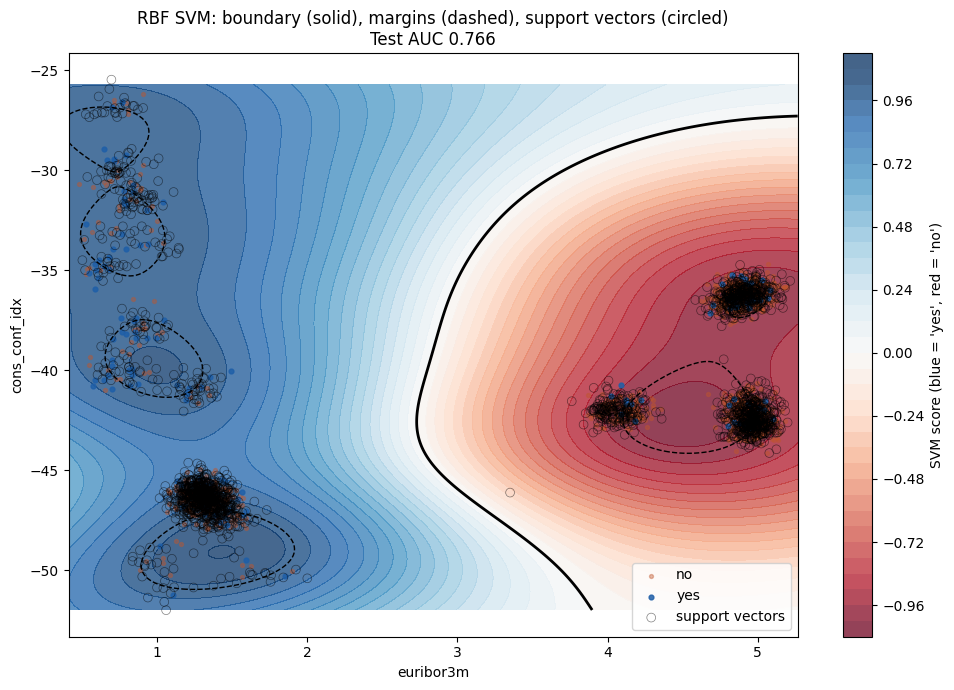

In [30]:

# An SVM boundary can only be drawn in 2D, so train on two features (change these freely)
# Fit on a 4,000-row sample: keeps the plot readable and the SVM fast
idx = X_train.sample(4000, random_state=0).index
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced"))
svm.fit(X_train.loc[idx], y_train.loc[idx])
auc = roc_auc_score(y_test, svm.decision_function(X_test))

clf, scaler = svm[-1], svm[0]
sv = scaler.inverse_transform(clf.support_vectors_)          # support vectors in original units
print(f"Support vectors: {len(sv)} of 4000 training rows ({len(sv)/4000:.0%}) | test AUC {auc:.3f}")

pad = lambda s: (s.min() - 0.05 * np.ptp(s), s.max() + 0.05 * np.ptp(s))
(x0, x1), (y0, y1) = pad(X[F1]), pad(X[F2])
xx, yy = np.meshgrid(np.linspace(x0, x1, 250), np.linspace(y0, y1, 250))
Z = svm.decision_function(pd.DataFrame({F1: xx.ravel(), F2: yy.ravel()})).reshape(xx.shape)

rng = np.random.RandomState(0)
jit = lambda v, f: v + rng.normal(0, 0.02 * np.ptp(X[f]), len(v))
pts = X_train.loc[idx].sample(1200, random_state=1); py = y_train.loc[pts.index]

fig, ax = plt.subplots(figsize=(10, 7))
lim = np.abs(Z).max()
cf = ax.contourf(xx, yy, Z, levels=40, cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim), alpha=0.75)
ax.contour(xx, yy, Z, levels=[0], colors="black", linewidths=2)                        # decision boundary
ax.contour(xx, yy, Z, levels=[-1, 1], colors="black", linewidths=1, linestyles="--")  # margins
ax.scatter(jit(pts[F1], F1)[py == 0], jit(pts[F2], F2)[py == 0], s=8, c="#C0562B", alpha=0.4, label="no")
ax.scatter(jit(pts[F1], F1)[py == 1], jit(pts[F2], F2)[py == 1], s=12, c="#1F5FA8", alpha=0.85, label="yes")
ax.scatter(jit(pd.Series(sv[:, 0]), F1), jit(pd.Series(sv[:, 1]), F2), s=40, facecolors="none",
           edgecolors="black", linewidths=0.5, alpha=0.5, label="support vectors")
fig.colorbar(cf, ax=ax, label="SVM score (blue = 'yes', red = 'no')")
ax.set_xlabel(F1); ax.set_ylabel(F2)
ax.set_title(f"RBF SVM: boundary (solid), margins (dashed), support vectors (circled)\nTest AUC {auc:.3f}")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("images/svm_plot.png", dpi=150, bbox_inches="tight"); plt.show()

##Final Takeaways

**Best choice:** the decision tree or logistic regression, with differences too small to separate on a single split. Use the tree if you want explainable rules and the best F1, and logistic regression for smoother scores and interpretable coefficients.

**Drop the SVM.** It’s slowest and weakest.

**Improvement over earlier problems:** with only the 7 bank features the best AUC was about 0.66. Adding the contact and economic features raised it to about 0.80, so better features mattered much more than better algorithms.

**Caveats:** the economic features tie these results to one campaign period, so performance may differ in another economic climate. The threshold was chosen to maximize F1, and you may want one based on the cost of a call versus the value of a subscription.

Questions

